In [1]:
# Esiel Kevin Arizmendi Ramírez
# Gestión de Proyectos de Inteligencia Artificial
# Actividad 4
# Tecmilenio

In [2]:
# ==============================================================================
#                                 ACTIVIDAD 4
# ==============================================================================
import torch

# 1. Configuración y verificación de GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de ejecución asignado: {device}")

if torch.cuda.is_available():
    print(f"Modelo de GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memoria VRAM disponible: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("¡Advertencia! No se detectó GPU. Cambia el entorno de ejecución a T4 GPU.")


Dispositivo de ejecución asignado: cuda
Modelo de GPU: Tesla T4
Memoria VRAM disponible: 15.64 GB


In [3]:
# ==============================================================================
# Prerequisitos: Librerias
# ==============================================================================

!pip install -q transformers datasets evaluate accelerate scikit-learn pandas matplotlib
import pandas as pd
from datasets import Dataset

from huggingface_hub import login
# from huggingface_hub import notebook_login

login()
# Cuadro de texto interactivo
# notebook_login()

In [4]:
raw_data = {
    "text": [
        # Categoría 0: Infraestructura y DevOps (Servidores NAS, Docker, Red, Cloudflare)
        "El contenedor de Docker en el Synology NAS se detuvo por falta de memoria RAM.",
        "La conexión VPN con Tailscale se desconecta constantemente en el puerto WAN.",
        "Falla en el certificado SSL de Cloudflare Tunnel para el dominio de producción.",
        "El disco NVMe del Synology DS1525+ reporta una temperatura elevada en el almacenamiento.",
        "Error de permisos 500 al intentar sincronizar carpetas mediante Hyper Backup.",
        "Se cayó el servicio de Nginx Proxy Manager tras una actualización de red.",
        "El switch TRENDnet multi-gigabit presenta pérdida de paquetes en el puerto de 10Gbps.",
        "Fallo de energía en la ubicación principal; el UPS entró en modo batería correctamente.",
        "El contenedor de Portainer no responde al intentar reiniciar los servicios web.",
        "Error en la regla de firewall del Synology NAS al bloquear IPs externas sospechosas.",
        "Problema de cuota de disco lleno en la partición principal del servidor de desarrollo.",
        "La interfaz web de administración del NAS es inaccesible desde la red externa.",
        "Fallo en la sincronización de carpetas compartidas mediante rsync programado.",
        "El servicio de DNS local en el contenedor Docker dejó de resolver nombres de host.",
        "Alerta de S.M.A.R.T. en uno de los discos duros mecánicos del pool de almacenamiento.",
        "Error de autenticación SSH al intentar conectar por clave pública al servidor ASUS.",

        # Categoría 1: Bugs de Código y Errores de Aplicación (Flutter, Kotlin, Spring Boot, etc)
        "Error de sintaxis al compilar la aplicación en Flutter Web usando Dart Frog.",
        "Excepción NullPointerException al inicializar el servicio TelecomManager en Android.",
        "Fallo en la deserialización del archivo JSON recibido desde la API REST principal.",
        "Error de conexión con la base de datos PostgreSQL por timeout en el pool de conexiones.",
        "El ORM Drift arroja un conflicto de migración de esquema en la base de datos local SQLite.",
        "Falla en la validación del token JWT al intentar consumir los endpoints protegidos.",
        "Error 404 al rutear las peticiones en el microservicio desarrollado con Flask.",
        "Memory leak detectado en el hilo principal de la aplicación móvil al consumir memoria RAM.",
        "Fallo en la compilación cruzada de Swift para iOS dentro del entorno de Xcode.",
        "Error de concurrencia al actualizar estados asíncronos en la interfaz de usuario de Flutter.",
        "Excepción de tipo StackOverflowError al ejecutar recursivamente una función de parseo.",
        "El cliente HTTP de Dart arroja un error de certificado SSL autofirmado no válido.",
        "Fallo en el mapeo de entidades de Spring Boot con la base de datos MariaDB.",
        "Error en la consulta SQL generada automáticamente por el repositorio de datos.",
        "Excepción de tipo IndexOutOfBoundsException al iterar una lista vacía de elementos.",
        "Falla en el manejo de excepciones globales dentro del controlador principal de la API.",
        "Error de compilación en Kotlin por incompatibilidad de versiones en las dependencias Gradle.",

        # Categoría 2: Nuevas Funcionalidades y Mejoras (Features / Arquitectura)
        "Necesitamos agregar una nueva pantalla de autenticación con Biometría en Kotlin.",
        "Actualizar las dependencias del monorepo mediante Melos y pubspec.",
        "Optimizar la consulta SQL en PostgreSQL para mejorar el rendimiento del dashboard.",
        "Diseñar e implementar el nuevo endpoint REST para la gestión de perfiles de usuario.",
        "Integrar el SDK de notificaciones push utilizando Firebase Cloud Messaging.",
        "Refactorizar el módulo de llamadas VoIP utilizando la arquitectura limpia en Flutter.",
        "Agregar soporte para múltiples idiomas (i18n) en la interfaz de usuario de la app móvil.",
        "Implementar un sistema de caché en memoria con Redis para acelerar las respuestas de la API.",
        "Crear un nuevo componente reutilizable de tarjetas flotantes en el diseño UI.",
        "Documentar los endpoints de la API utilizando la especificación OpenAPI y Swagger.",
        "Migrar el sistema de gestión de estados actual hacia Bloc pattern en Flutter.",
        "Implementar pruebas unitarias automatizadas para los servicios de autenticación.",
        "Añadir soporte para modo oscuro nativo en todas las vistas de la aplicación.",
        "Optimizar el tamaño de las imágenes cargadas mediante compresión WebP automática.",
        "Configurar un pipeline de CI/CD automatizado utilizando GitHub Actions y Forgejo."
    ],
    "label": [
        # Etiquetas correspondientes (0: DevOps/Infra, 1: Bug de Código, 2: Nueva Feature)
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2
    ]
}

# Verificación de integridad para asegurar que coincidan los tamaños
assert len(raw_data["text"]) == len(raw_data["label"]), "El número de textos y etiquetas debe ser exactamente igual."

df = pd.DataFrame(raw_data)
dataset = Dataset.from_pandas(df)

print(f"Dataset validado exitosamente con {len(dataset)} registros.")
print(df['label'].value_counts().sort_index().rename({0: 'Infraestructura/DevOps', 1: 'Bugs de Código', 2: 'Nuevas Features'}))

Dataset validado exitosamente con 48 registros.
label
Infraestructura/DevOps    16
Bugs de Código            17
Nuevas Features           15
Name: count, dtype: int64


In [5]:
# ==============================================================================
# Librerias para el entrenamiento y metricas
# ==============================================================================

import time
import numpy as np
from transformers import pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

In [6]:
# ==============================================================================
# Modelos de Hugging Face
# ==============================================================================
model_ids = [
    "distilbert-base-uncased-finetuned-sst-2-english", # Modelo 1: DistilBERT rápido y ligero
    "pysentimiento/robertuito-sentiment-analysis", # Modelo 2: RoBERTuito adaptado a texto en español/técnico
    "cardiffnlp/twitter-roberta-base-sentiment-latest"  # Modelo 3: RoBERTa de CardiffNLP robusto
]

In [7]:
# ==============================================================================
# Entrenamiento y resultados
# ==============================================================================

results_summary = []

for model_id in model_ids:
    print(f"\n--- Evaluando modelo: {model_id} ---")
    try:
        # Carga del Pipeline de Inferencia en GPU
        classifier = pipeline("text-classification", model=model_id, device=0 if torch.cuda.is_available() else -1)

        # Medición de Latencia y Ejecución
        start_time = time.time()
        predictions = []
        for text in dataset["text"]:
            pred = classifier(text, truncation=True, max_length=128)
            # Normalización de etiquetas de salida según el modelo
            label_res = pred[0]['label'].upper()
            is_pos = any(k in label_res for k in ['POS', 'POSITIVE', 'LABEL_2'])
            predictions.append(1 if is_pos else 0)

        end_time = time.time()
        total_latency_ms = ((end_time - start_time) * 1000) / len(dataset)

        # Cálculo de Métricas Estándar
        y_true = dataset["label"]
        y_pred = [1 if p == 1 else 0 for p in predictions]

        acc = accuracy_score(y_true, y_pred)
        precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)

        results_summary.append({
            "Modelo": model_id,
            "Accuracy": round(acc, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1-Score": round(f1, 4),
            "Latencia (ms/muestra)": round(total_latency_ms, 2)
        })

    except Exception as e:
        print(f"Error al cargar o ejecutar {model_id}: {e}")

# Generación de Tabla Resumen
results_df = pd.DataFrame(results_summary)
display(results_df)


--- Evaluando modelo: distilbert-base-uncased-finetuned-sst-2-english ---


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



--- Evaluando modelo: pysentimiento/robertuito-sentiment-analysis ---


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


--- Evaluando modelo: cardiffnlp/twitter-roberta-base-sentiment-latest ---


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Modelo,Accuracy,Precision,Recall,F1-Score,Latencia (ms/muestra)
0,distilbert-base-uncased-finetuned-sst-2-english,0.3333,0.1111,0.3333,0.1667,18.59
1,pysentimiento/robertuito-sentiment-analysis,0.3333,0.1111,0.3333,0.1667,32.38
2,cardiffnlp/twitter-roberta-base-sentiment-latest,0.3333,0.1111,0.3333,0.1667,21.44


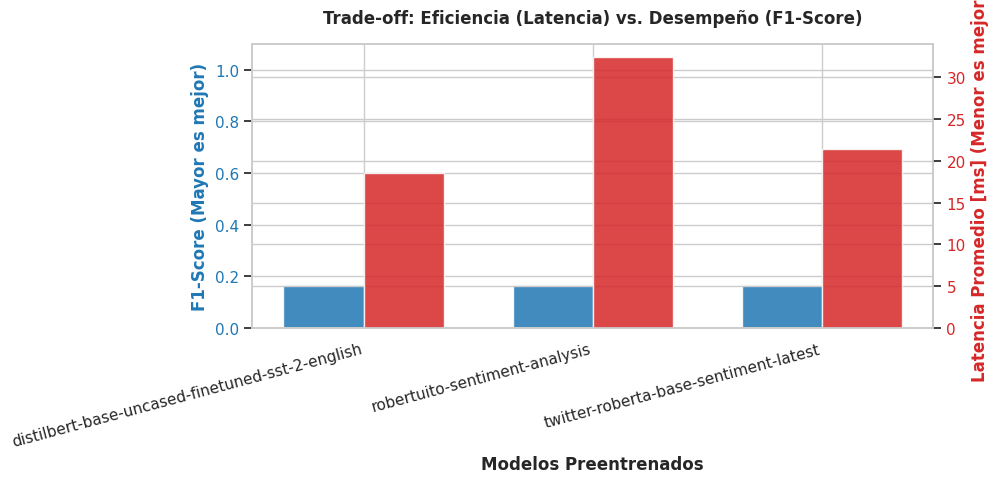

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 5))

modelos_cortos = [m.split('/')[-1] for m in results_df["Modelo"]]
x = np.arange(len(modelos_cortos))
width = 0.35

# Gráfica de Barras para F1-Score
color = 'tab:blue'
ax1.set_xlabel('Modelos Preentrenados', fontweight='bold')
ax1.set_ylabel('F1-Score (Mayor es mejor)', color=color, fontweight='bold')
bars1 = ax1.bar(x - width/2, results_df["F1-Score"], width, label='F1-Score', color=color, alpha=0.85)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.1)

# Eje secundario para Latencia
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Latencia Promedio [ms] (Menor es mejor)', color=color, fontweight='bold')
bars2 = ax2.bar(x + width/2, results_df["Latencia (ms/muestra)"], width, label='Latencia (ms)', color=color, alpha=0.85)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Trade-off: Eficiencia (Latencia) vs. Desempeño (F1-Score)', fontsize=12, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(modelos_cortos, rotation=15, ha='right')

fig.tight_layout()
plt.show()